In [6]:
import oqupy
import numpy as np
import matplotlib.pyplot as plt

In [7]:
sigma_x = oqupy.operators.sigma("x")
sigma_y = oqupy.operators.sigma("y")
sigma_z = oqupy.operators.sigma("z")
up_density_matrix = oqupy.operators.spin_dm("z+")
down_density_matrix = oqupy.operators.spin_dm("z-")

In [8]:
Delta = 1.
omega_cutoff = 10.
alpha = 0.1

start_time = 0.
end_time = 3. * np.pi

system = oqupy.System(Delta * sigma_x)

correlations = oqupy.PowerLawSD(alpha= np.pi * alpha / 8,
                                zeta=1,
                                cutoff=omega_cutoff,
                                cutoff_type='exponential',
                                temperature=0.)
bath = oqupy.Bath(sigma_z, correlations)

In [4]:
# tolerance = 0.01
# tempo_parameters = oqupy.guess_tempo_parameters(system=system,
#                                                 bath=bath,
#                                                 start_time=start_time,
#                                                 end_time=end_time,
#                                                 tolerance=tolerance)
# 
# print(tempo_parameters)

C:\Users\mirko\miniconda3\envs\venv3.12\Lib\site-packages\oqupy\tempo.py:1106: UserWarning: Estimating TEMPO parameters. No guarantee subsequent dynamics calculations are converged. Please refer to the TEMPO documentation and check convergence by varying the parameters manually.
  warnings.warn(GUESS_WARNING_MSG, UserWarning)
C:\Users\mirko\miniconda3\envs\venv3.12\Lib\site-packages\oqupy\bath_correlations.py:318: IntegrationWarning: The maximum number of subdivisions (256) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  re_int = integrate.quad(lambda x: np.real(integrand(x)),
C:\Users\mirko\miniconda3\envs\venv3.12\Lib\site-packages\oqupy\b

----------------------------------------------
TempoParameters object: Roughly estimated parameters
 Estimated with 'guess_tempo_parameters()' based on bath correlations (limiting) and system frequencies.
  dt                   = 0.1571 
  tcut [dkmax]         = 25.2931 [161] 
  epsrel               = 2.16e-07 
  add_correlation_time = None 



In [11]:
# tempo_parameters = oqupy.TempoParameters(dt=tempo_parameters.dt, tcut=tempo_parameters.tcut,
#                                          epsrel=tempo_parameters.epsrel)

tempo_parameters = oqupy.TempoParameters(dt=0.2, tcut=end_time/4, epsrel=1e-5)

tempo = oqupy.Tempo(system=system,
                    bath=bath,
                    parameters=tempo_parameters,
                    initial_state=up_density_matrix,
                    start_time=start_time,
                    unique=False)

tempo.compute(end_time=end_time)

--> TEMPO computation:
100.0%   47 of   47 [########################################] 00:00:02
Elapsed time: 2.9s


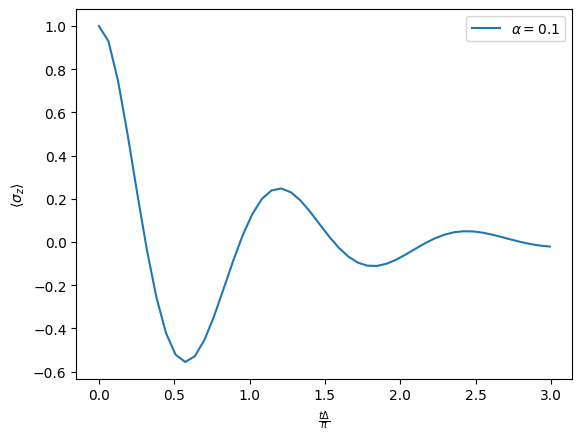

In [12]:
dynamics = tempo.get_dynamics()
t_list, sigma_z_list = dynamics.expectations(sigma_z, real=True)
plt.plot(t_list * Delta / np.pi, sigma_z_list, label=fr'$\alpha={alpha:.1f}$')
plt.xlabel(r'$\frac{t\Delta}{\pi}$')
plt.ylabel(r'$\langle\sigma_z\rangle$')
plt.legend()